# 07.2 — Extrinsic Value

At expiry, an option's pay-off is its intrinsic value; its extrinsic value is zero. For a call with strike $K=100$:

$$
C_T = \max(S_T-K,0) = \max(S_T-100,0).
$$

## Before expiry

Before expiry, a call's value combines its intrinsic value, $\max(S_t-K,0)$, and extrinsic value reflecting the possibility of finishing in the money and the size of its future pay-off.

We model the non-dividend-paying underlying using risk-neutral geometric Brownian motion, with constant risk-free rate $r$ and volatility $\sigma$:

$$
dS_t=rS_t\,dt+\sigma S_t\,dW_t.
$$

Starting from $S_0$, $S_t=S_0\exp[(r-\tfrac12\sigma^2)t+\sigma W_t]$. Given today's price $S_t$, the price at expiry $T$ is therefore sampled as

$$
S_T=S_t\exp\left[(r-\tfrac12\sigma^2)(T-t)+\sigma\sqrt{T-t}\,Z\right],
\qquad Z\sim\mathcal N(0,1).
$$

For a European call, average the sampled pay-offs and discount them to time $t$:

$$
C_t=e^{-r(T-t)}\mathbb E^{\mathbb Q}[\max(S_T-K,0)\mid S_t]
\approx e^{-r(T-t)}\frac1N\sum_{i=1}^N\max(S_T^{(i)}-K,0).
$$

Here we interpret **10 as days remaining to expiry**, so $T-t=10/365$ years, and fix $r=5\%$, $\sigma=20\%$, and $K=100$. The orange curve shows the estimated call value at each current underlying price; its height above intrinsic value is extrinsic value.


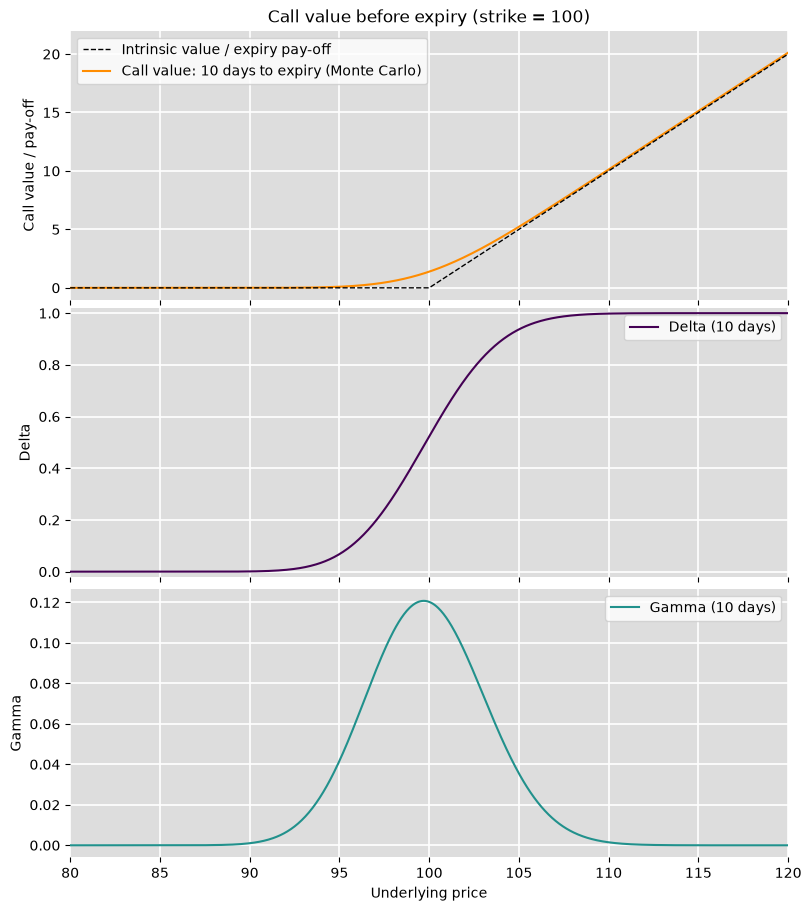

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm

risk_free_rate = 0.05
volatility = 0.20
strike = 100
days_to_expiry = 10
time_to_expiry = days_to_expiry / 365
underlying_price = np.linspace(80, 120, 801)
call_payoff = np.maximum(underlying_price - strike, 0)
n_samples = 100_000
rng = np.random.default_rng(42)

# Reuse the same draws across prices for a smoother comparison.
z = rng.standard_normal(n_samples)
terminal_growth = np.exp(
    (risk_free_rate - 0.5 * volatility**2) * time_to_expiry
    + volatility * np.sqrt(time_to_expiry) * z
)
discount_factor = np.exp(-risk_free_rate * time_to_expiry)
call_value = np.array(
    [
        discount_factor * np.maximum(spot * terminal_growth - strike, 0).mean()
        for spot in underlying_price
    ]
)

d1 = (
    np.log(underlying_price / strike)
    + (risk_free_rate + 0.5 * volatility**2) * time_to_expiry
) / (volatility * np.sqrt(time_to_expiry))
delta = norm.cdf(d1)
gamma = norm.pdf(d1) / (underlying_price * volatility * np.sqrt(time_to_expiry))

fig, (value_ax, delta_ax, gamma_ax) = plt.subplots(
    3, 1, sharex=True, figsize=(8, 9), layout="constrained"
)
for ax in (value_ax, delta_ax, gamma_ax):
    ax.set_facecolor("#dddddd")
    ax.set_axisbelow(True)
    ax.grid(color="white", linewidth=1.2)

value_ax.plot(
    underlying_price,
    call_payoff,
    color="black",
    linewidth=1,
    zorder=3,
    label="Intrinsic value / expiry pay-off",
    linestyle="--",
)
value_ax.plot(
    underlying_price,
    call_value,
    color="darkorange",
    linewidth=1.5,
    zorder=2,
    label="Call value: 10 days to expiry (Monte Carlo)",
)
value_ax.set(
    ylabel="Call value / pay-off",
    title="Call value before expiry (strike = 100)",
    xlim=(80, 120),
    ylim=(-1, 22),
)
value_ax.legend()

delta_ax.plot(
    underlying_price,
    delta,
    color="#440154",
    linewidth=1.5,
    label=f"Delta ({days_to_expiry} days)",
)
delta_ax.set(ylabel="Delta", ylim=(-0.02, 1.02))
delta_ax.legend()
gamma_ax.plot(
    underlying_price,
    gamma,
    color="#21918c",
    linewidth=1.5,
    label=f"Gamma ({days_to_expiry} days)",
)
gamma_ax.set(xlabel="Underlying price", ylabel="Gamma")
gamma_ax.legend()

for ax in (value_ax, delta_ax, gamma_ax):
    for spine in ax.spines.values():
        spine.set_visible(False)
plt.show()

## Delta, gamma, and time to expiry

**Delta** is the slope of the call-value curve with respect to the underlying price, holding other inputs fixed:

$$
\Delta=\frac{\partial C}{\partial S},\qquad 0<\Delta<1
$$

for $S>0$, positive volatility, and time remaining. Intrinsic value has slope $0$ below the strike and $1$ above it; the largest difference in slope is around the strike.

**Gamma** measures how quickly delta changes:

$$
\Gamma=\frac{\partial\Delta}{\partial S}=\frac{\partial^2 C}{\partial S^2}.
$$

Gamma is positive (delta monotonically increases) and peaks near the strike, though not necessarily exactly at it. As expiry approaches, call values converge to intrinsic value and the change in delta becomes sharper near the strike; further from expiry, the curves are smoother and extrinsic value extends over a wider range of prices.

Below, calls share $K=100$, $r=5\%$, and $\sigma=20\%$, with **1 to 365 days remaining**. We use the Black–Scholes formula (the exact discounted expectation under the same model) to avoid sampling noise in the curves:

$$
C=S\Phi(d_1)-Ke^{-r\tau}\Phi(d_2),\qquad
d_1=\frac{\ln(S/K)+(r+\tfrac12\sigma^2)\tau}{\sigma\sqrt{\tau}},\qquad
d_2=d_1-\sigma\sqrt{\tau},
$$

where $\tau=T-t$ and $\Phi$ is the standard normal cumulative distribution function.


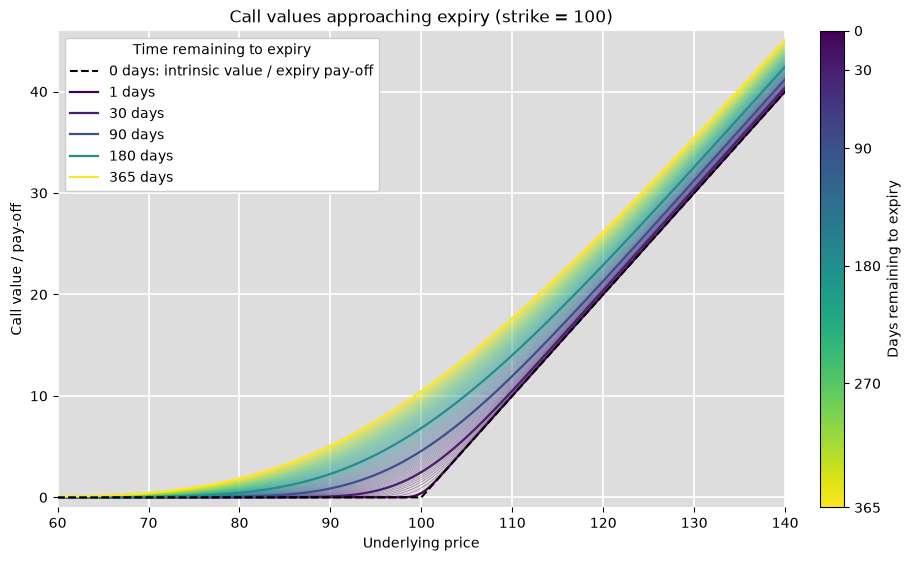

In [2]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from scipy.stats import norm

spot_prices = np.linspace(40, 160, 2401)
reference_days = np.array([1, 30, 90, 180, 365])
expiry_days = np.unique(np.concatenate([np.linspace(1, 365, 100), reference_days]))
colour_scale = Normalize(vmin=0, vmax=365)
colour_map = plt.get_cmap("viridis")

fig, ax = plt.subplots(figsize=(9, 5.5), layout="constrained")
ax.set_facecolor("#dddddd")
ax.set_axisbelow(True)
ax.grid(color="white", linewidth=1.2)

for days in expiry_days:
    tau = days / 365
    d1 = (
        np.log(spot_prices / strike) + (risk_free_rate + 0.5 * volatility**2) * tau
    ) / (volatility * np.sqrt(tau))
    d2 = d1 - volatility * np.sqrt(tau)
    values = spot_prices * norm.cdf(d1) - strike * np.exp(
        -risk_free_rate * tau
    ) * norm.cdf(d2)
    is_reference = days in reference_days
    ax.plot(
        spot_prices,
        values,
        color=colour_map(colour_scale(days)),
        linewidth=1.6 if is_reference else 0.5,
        alpha=1 if is_reference else 0.45,
        zorder=3 if is_reference else 2,
        label=f"{int(days)} days" if is_reference else None,
    )

ax.plot(
    spot_prices,
    np.maximum(spot_prices - strike, 0),
    color="black",
    linewidth=1.5,
    linestyle="--",
    zorder=4,
    label="0 days: intrinsic value / expiry pay-off",
)
colour_bar = fig.colorbar(
    ScalarMappable(norm=colour_scale, cmap=colour_map),
    ax=ax,
    orientation="vertical",
    pad=0.03,
)
colour_bar.set_label("Days remaining to expiry")
colour_bar.set_ticks([0, 30, 90, 180, 270, 365])
colour_bar.minorticks_off()
colour_bar.ax.invert_yaxis()
ax.set(
    xlabel="Underlying price",
    ylabel="Call value / pay-off",
    title="Call values approaching expiry (strike = 100)",
    xlim=(60, 140),
    ylim=(-1, 46),
)
for spine in ax.spines.values():
    spine.set_visible(False)
handles, labels = ax.get_legend_handles_labels()
ax.legend(
    [handles[-1], *handles[:-1]],
    [labels[-1], *labels[:-1]],
    loc="upper left",
    title="Time remaining to expiry",
    framealpha=1,
)
plt.show()

Compared with near-expiry calls, longer-dated calls have generally higher gamma away from the strike; as expiry approaches, gamma becomes increasingly concentrated near the strike and diminishes elsewhere.

This is supported by the Black–Scholes gamma formula:

$$
\Gamma=\frac{\partial^2 C}{\partial S^2}
=\frac{\phi(d_1)}{S\sigma\sqrt{\tau}},
\qquad
d_1=\frac{\ln(S/K)+(r+\tfrac12\sigma^2)\tau}{\sigma\sqrt{\tau}},
\qquad \tau=T-t,
$$

where $\phi$ is the standard normal probability density. As $\tau\to0$, gamma grows without bound at $S=K$ but tends to zero at any fixed $S\ne K$, producing an increasingly tall, narrow peak near the strike.

The same time-to-expiry comparison for the Greeks: delta and gamma are shown for the same strike and expiry schedule as the call-value plot.

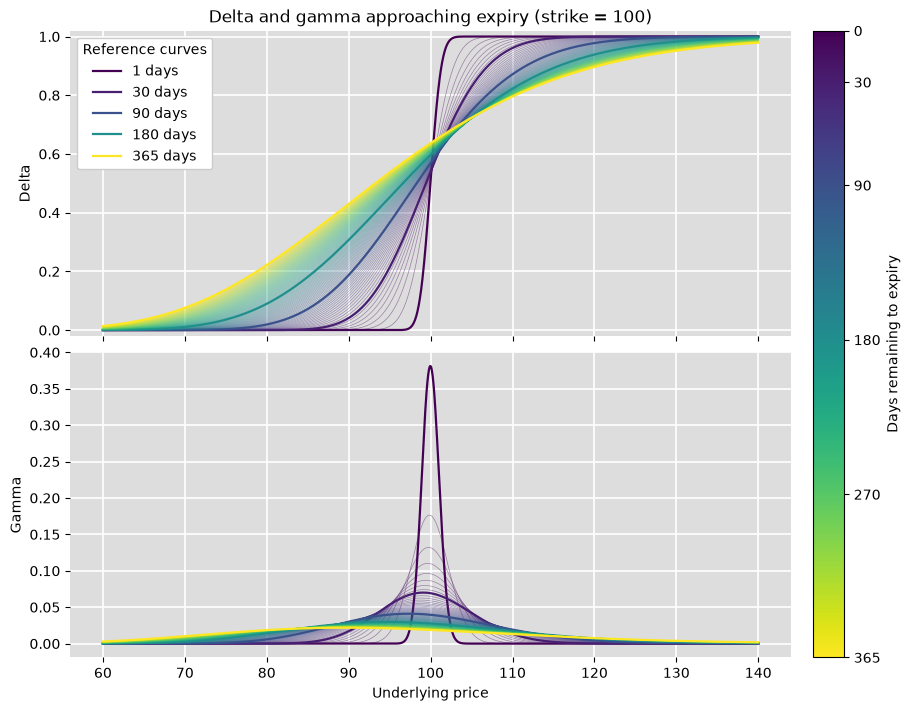

In [3]:
greek_spot_prices = np.linspace(60, 140, 1601)
greek_fig, (delta_ax, gamma_ax) = plt.subplots(
    2, 1, sharex=True, figsize=(9, 7), layout="constrained"
)
for ax in (delta_ax, gamma_ax):
    ax.set_facecolor("#dddddd")
    ax.set_axisbelow(True)
    ax.grid(color="white", linewidth=1.2)

for days in expiry_days:
    tau = days / 365
    d1 = (
        np.log(greek_spot_prices / strike)
        + (risk_free_rate + 0.5 * volatility**2) * tau
    ) / (volatility * np.sqrt(tau))
    line_colour = colour_map(colour_scale(days))
    is_reference = days in reference_days
    line_width = 1.6 if is_reference else 0.5
    line_alpha = 1 if is_reference else 0.45
    delta_ax.plot(
        greek_spot_prices,
        norm.cdf(d1),
        color=line_colour,
        linewidth=line_width,
        alpha=line_alpha,
        label=f"{int(days)} days" if is_reference else None,
    )
    gamma_ax.plot(
        greek_spot_prices,
        norm.pdf(d1) / (greek_spot_prices * volatility * np.sqrt(tau)),
        color=line_colour,
        linewidth=line_width,
        alpha=line_alpha,
    )

delta_ax.set(
    ylabel="Delta",
    ylim=(-0.02, 1.02),
    title="Delta and gamma approaching expiry (strike = 100)",
)
gamma_ax.set(xlabel="Underlying price", ylabel="Gamma")
colour_bar = greek_fig.colorbar(
    ScalarMappable(norm=colour_scale, cmap=colour_map),
    ax=(delta_ax, gamma_ax),
    orientation="vertical",
    pad=0.03,
)
colour_bar.set_label("Days remaining to expiry")
colour_bar.set_ticks([0, 30, 90, 180, 270, 365])
colour_bar.minorticks_off()
colour_bar.ax.invert_yaxis()
delta_ax.legend(title="Reference curves", loc="upper left", framealpha=1)
for ax in (delta_ax, gamma_ax):
    for spine in ax.spines.values():
        spine.set_visible(False)
plt.show()

### Intuition

Gamma is greatest near, specifically for calls slightly below, the strike because delta (the risk-neutral probability of finishing in the money—changes) fastest there. As expiry approaches, this transition becomes sharper and gamma's peak converges to the strike.